<a href="https://colab.research.google.com/github/ajaykumar080286/DeepLearning/blob/master/34_1_final_cat_dog_normal_augmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from keras.preprocessing import image
from tensorflow.keras.preprocessing.image import ImageDataGenerator, array_to_img, img_to_array, load_img

In [4]:
import pandas as pd
import numpy as np

import tensorflow as tf
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense, Dropout,Flatten,MaxPool2D, Conv2D,BatchNormalization

import matplotlib.pyplot as plt
import seaborn as sns


import zipfile
import requests
import os

In [8]:
# Path to your zip file (URL)
zip_url = "https://raw.githubusercontent.com/ajaykumar080286/DeepLearning/master/dogs_vs_cats_Augmentation.zip"

# Local path to save the downloaded zip file
local_zip_path = "/content/dogs_vs_cats.zip"

# Download the zip file
print(f"Downloading {zip_url} to {local_zip_path}...")
response = requests.get(zip_url)
response.raise_for_status() # Raise an exception for HTTP errors
with open(local_zip_path, 'wb') as f:
    f.write(response.content)
print("Download complete.")

# Open the zip file
zip_ref = zipfile.ZipFile(local_zip_path, 'r')
zip_ref.extractall("/content")
zip_ref.close()
print("Extraction complete.")

# Optionally, remove the downloaded zip file after extraction
os.remove(local_zip_path)

Download complete.
Extraction complete.


In [9]:
batch_size=16
# this is the augmentation configuration we will use for training
train_datagen = ImageDataGenerator(
        rescale=1./255,
        shear_range=0.2,
        zoom_range=0.2,
        horizontal_flip=True)

# this is the augmentation configuration we will use for testing:
# only rescaling
test_datagen = ImageDataGenerator(rescale=1./255)

In [11]:
# this is a generator that will read pictures found in
# subfolers of 'data/train', and indefinitely generate
# batches of augmented image data
train_generator = train_datagen.flow_from_directory(
        '/content/dogs_vs_cats/train',  # this is the target directory
        target_size=(150, 150),  # all images will be resized to 150x150
        batch_size=batch_size,
        class_mode='binary')  # since we use binary_crossentropy loss, we need binary labels

# this is a similar generator, for validation data
validation_generator = test_datagen.flow_from_directory(
        '/content/dogs_vs_cats/valid',
        target_size=(150, 150),
        batch_size=batch_size,
        class_mode='binary')

Found 2 images belonging to 2 classes.
Found 2 images belonging to 2 classes.


In [22]:
model=Sequential()

model.add(Conv2D(32, kernel_size=(3,3), activation="relu", input_shape=(150,150,3)))
model.add(MaxPool2D(pool_size=(2,2)))

model.add(Conv2D(32, kernel_size=(3,3), activation="relu"))
model.add(MaxPool2D(pool_size=(2,2)))

model.add(Conv2D(64, kernel_size=(3,3), activation="relu"))
model.add(MaxPool2D(pool_size=(2,2)))

model.add(Flatten())

model.add(Dense(64, activation="relu"))
model.add(Dense(1, activation="sigmoid"))

In [23]:
model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_13 (Conv2D)              │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 72, 72, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 36, 36, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 34, 34, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 17, 17, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 18496)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │     1,183,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,212,513 (4.63 MB)

 Trainable params: 1,212,513 (4.63 MB)

 Non-trainable params: 0 (0.00 B)

In [24]:
model.compile(loss='binary_crossentropy',
              optimizer='rmsprop',
              metrics=['accuracy'])

In [25]:
model.fit(train_generator, epochs=10, validation_data=validation_generator)

Epoch 1/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step - accuracy: 1.0000 - loss: 0.6560 - val_accuracy: 1.0000 - val_loss: 0.0269
Epoch 2/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 212ms/step - accuracy: 1.0000 - loss: 0.0457 - val_accuracy: 1.0000 - val_loss: 7.2926e-05
Epoch 3/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step - accuracy: 1.0000 - loss: 4.4439e-05 - val_accuracy: 1.0000 - val_loss: 6.4540e-05
Epoch 4/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 194ms/step - accuracy: 1.0000 - loss: 0.0205 - val_accuracy: 0.5000 - val_loss: 5.9136
Epoch 5/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 198ms/step - accuracy: 0.5000 - loss: 5.9841 - val_accuracy: 0.5000 - val_loss: 5.5642
Epoch 6/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step - accuracy: 0.5000 - loss: 5.7065 - val_accuracy: 1.0000 - val_loss: 0.1749
Epoch 7/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step - accuracy: 1.0000 - loss: 0.2498 - val_accuracy: 1.0000 - val_loss: 0.1731
Epoch 8/10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 209ms/step - accuracy: 0.5000 - loss: 0.3938 - val_accuracy: 1.0000 - 

In [35]:
import cv2
test_img=cv2.imread("/content/dogs_vs_cats/test/dogs/dog.10900.jpg")

array([[[117, 144, 178],
        [115, 142, 176],
        [111, 138, 172],
        ...,
        [ 86, 107, 138],
        [ 86, 107, 138],
        [ 86, 107, 138]],

       [[112, 139, 173],
        [110, 137, 171],
        [106, 133, 167],
        ...,
        [ 86, 108, 136],
        [ 86, 107, 138],
        [ 86, 107, 138]],

       [[107, 134, 168],
        [105, 132, 166],
        [102, 129, 163],
        ...,
        [ 87, 109, 137],
        [ 87, 109, 137],
        [ 87, 109, 137]],

       ...,

       [[118, 107,  87],
        [115, 104,  84],
        [112,  99,  77],
        ...,
        [114,  97,  71],
        [114,  97,  71],
        [114,  97,  71]],

       [[126, 115,  95],
        [122, 111,  91],
        [118, 105,  83],
        ...,
        [114,  97,  71],
        [114,  97,  71],
        [114,  97,  71]],

       [[124, 113,  93],
        [120, 109,  89],
        [117, 104,  82],
        ...,
        [114,  97,  71],
        [114,  97,  71],
        [114,  97,  71]]], shape=(340, 499, 3), dtype=uint8)
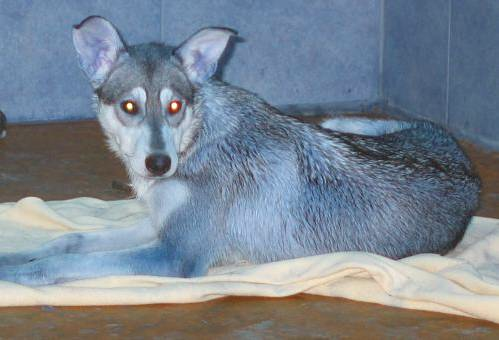

In [36]:
test_img

In [37]:
test_img=cv2.resize(test_img,(256,256))

In [38]:
test_input=test_img.reshape(1,256,256,3)

In [39]:
# Resize to the model's expected input shape (150, 150)
test_img_resized = cv2.resize(test_img, (150, 150))

# Rescale pixels (same as train/test ImageDataGenerator)
test_img_scaled = test_img_resized / 255.0

# Reshape to (1, 150, 150, 3)
test_input_fixed = test_img_scaled.reshape(1, 150, 150, 3)

# Make prediction
op=model.predict(test_input_fixed)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step


In [40]:
# 1. Manually specify the categories (using directory alphabetical order)
categories = ['cats', 'dogs']
print("Categories in dataset:", categories)

# 2. Get the model prediction index (0 or 1)
pred_idx = 1 if op[0][0] >= 0.5 else 0

# 3. Map the index to the class name
predicted_category = categories[pred_idx]
print(f"Prediction index: {pred_idx} -> Predicted Category: {predicted_category}")

Categories in dataset: ['cats', 'dogs']
Prediction index: 1 -> Predicted Category: dogs
